# Colour Spaces and Channels

The same image can be represented in many colour spaces, and choosing the right one makes hard problems easy. BGR/RGB describe colour as mixtures; grayscale keeps only brightness; HSV separates colour (hue) from brightness, which makes colour-based detection reliable under changing light. This notebook covers conversions and the classic HSV colour-detection pipeline.

## Setup

We import OpenCV (`cv2`), NumPy and Matplotlib. In these notebooks images are displayed with Matplotlib so the code runs everywhere, including servers without a screen. The classic OpenCV window functions are explained where they belong, with example code you can run on your own machine.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

def show(image, title="", cmap=None):
    """Display a BGR (or single-channel) image with matplotlib - works in any environment."""
    if len(image.shape) == 2:
        plt.imshow(image, cmap=cmap or "gray")
    else:
        plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()


OpenCV version: 4.10.0


## Converting between colour spaces

One function does every conversion: `cv2.cvtColor` with a code such as `COLOR_BGR2GRAY`, `COLOR_BGR2HSV` or `COLOR_BGR2RGB`. OpenCV stores colour as BGR; Matplotlib expects RGB - converting wrongly swaps red and blue.

BGR: (300, 400, 3) | Gray: (300, 400) | HSV: (300, 400, 3)


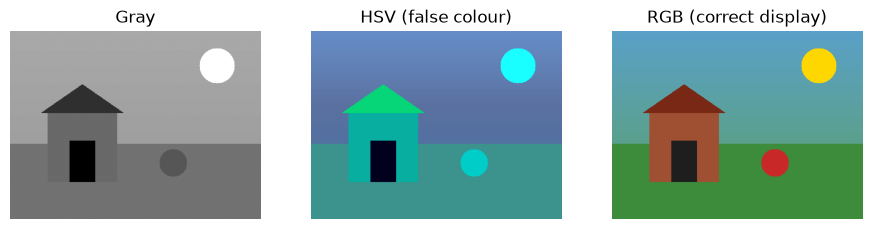

In [2]:
img = cv2.imread("../assets/test_image.png")
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
print("BGR:", img.shape, "| Gray:", gray.shape, "| HSV:", hsv.shape)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
axes[0].imshow(gray, cmap="gray"); axes[0].set_title("Gray")
axes[1].imshow(hsv); axes[1].set_title("HSV (false colour)")
axes[2].imshow(rgb); axes[2].set_title("RGB (correct display)")
for ax in axes: ax.axis("off")
plt.show()

## The HSV space explained

In OpenCV, Hue ranges 0-179 (half-degrees), Saturation 0-255 (purity) and Value 0-255 (brightness). Because hue isolates the colour itself, a red object stays 'red' in HSV even when a shadow halves its brightness - in BGR all three channels would change.

In [3]:
blocks = cv2.imread("../assets/color_blocks.png")
hsv_blocks = cv2.cvtColor(blocks, cv2.COLOR_BGR2HSV)
samples = {"blue block": (120, 60), "green block": (120, 160), "red block": (120, 260), "yellow block": (120, 360)}
for name, (y, x) in samples.items():
    print(name, "HSV =", hsv_blocks[y, x])

blue block HSV = [120 255 255]
green block HSV = [ 60 255 255]
red block HSV = [  0 255 255]
yellow block HSV = [ 30 255 255]


## Colour detection with inRange

`cv2.inRange` builds a binary mask of pixels inside a lower-upper HSV range. Red wraps around the hue circle, so it needs two ranges combined. The mask is the starting point for tracking, counting and measuring coloured objects.

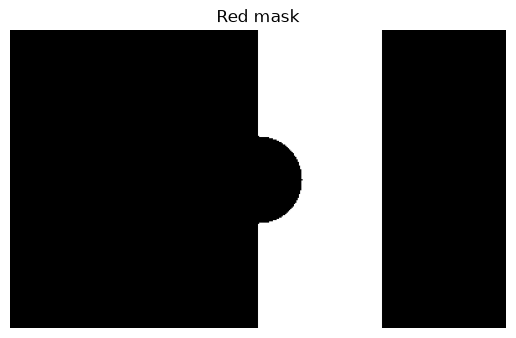

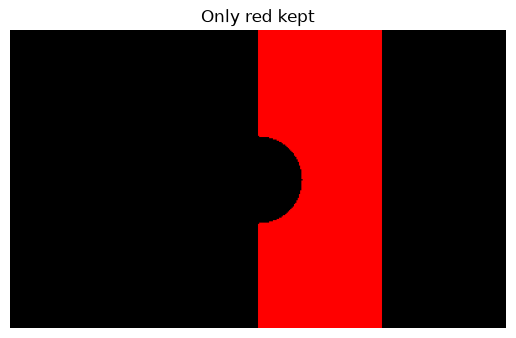

In [4]:
lower_red1, upper_red1 = np.array([0, 120, 70]), np.array([10, 255, 255])
lower_red2, upper_red2 = np.array([170, 120, 70]), np.array([179, 255, 255])
mask = cv2.inRange(hsv_blocks, lower_red1, upper_red1) + cv2.inRange(hsv_blocks, lower_red2, upper_red2)
result = cv2.bitwise_and(blocks, blocks, mask=mask)
show(mask, "Red mask")
show(result, "Only red kept")

## Finding the centre of a coloured object

Image moments of a mask give its area and centroid: `m10/m00` is the x centre and `m01/m00` is the y centre. This is the simplest possible object tracker - find the colour, compute the centroid, repeat per frame.

Red region centre: (252, 119) | area (pixels): 5619690.0


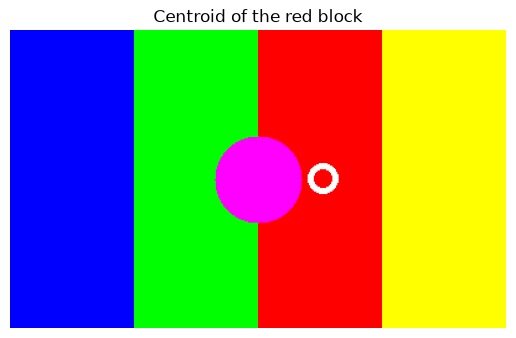

In [5]:
moments = cv2.moments(mask)
cx = int(moments["m10"] / moments["m00"])
cy = int(moments["m01"] / moments["m00"])
marked = blocks.copy()
cv2.circle(marked, (cx, cy), 10, (255, 255, 255), 3)
print("Red region centre:", (cx, cy), "| area (pixels):", moments["m00"])
show(marked, "Centroid of the red block")

## Other useful spaces: YCrCb, LAB and XYZ

YCrCb separates brightness (Y) from colour difference channels and is common in skin detection and video compression. LAB is designed so equal numeric distances look equally different to humans, which makes colour comparison and segmentation more meaningful.

YCrCb sample pixel: [138  94 135] | LAB sample pixel: [156 104 126]


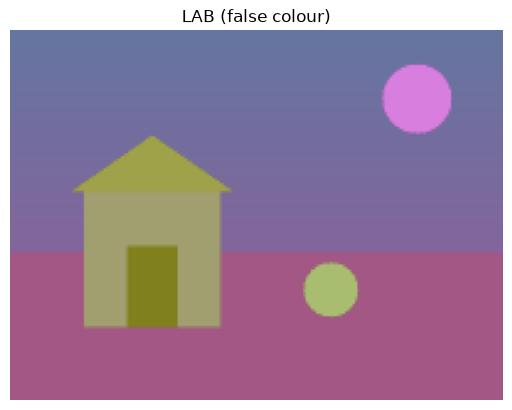

In [6]:
img_small = cv2.resize(img, (200, 150))
ycrcb = cv2.cvtColor(img_small, cv2.COLOR_BGR2YCrCb)
lab = cv2.cvtColor(img_small, cv2.COLOR_BGR2LAB)
print("YCrCb sample pixel:", ycrcb[75, 100], "| LAB sample pixel:", lab[75, 100])
show(lab, "LAB (false colour)")

## Splitting HSV channels and thresholding saturation

Low saturation means grey/white/black - no real colour. Thresholding the S channel is a quick way to separate coloured objects from a dull background, and the V channel shows pure brightness like grayscale but computed differently.

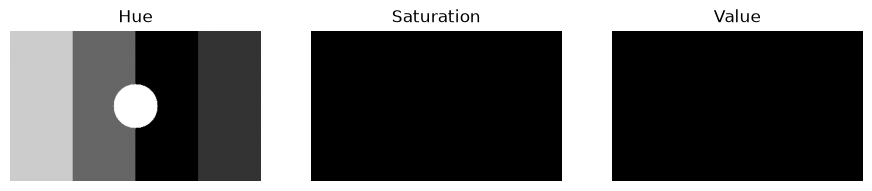

Colourful-area mask pixels: 96000


In [7]:
h, s, v = cv2.split(hsv_blocks)
_, colourful = cv2.threshold(s, 80, 255, cv2.THRESH_BINARY)
fig, axes = plt.subplots(1, 3, figsize=(11, 3))
for ax, ch, name in zip(axes, (h, s, v), ("Hue", "Saturation", "Value")):
    ax.imshow(ch, cmap="gray"); ax.set_title(name); ax.axis("off")
plt.show()
print("Colourful-area mask pixels:", int((colourful > 0).sum()))

## Key Points

- cvtColor converts between spaces; OpenCV colour order is BGR, displays expect RGB.
- HSV: Hue 0-179, Saturation and Value 0-255 in OpenCV.
- Colour detection = convert to HSV + inRange mask; red needs two hue ranges.
- Image moments of a mask give area and centroid - the simplest tracker.
- S in HSV separates coloured pixels from grey/white/black.

## Mini Task

1. Build an HSV mask for the green block in `color_blocks.png` (green hue is roughly 35-85).
2. Compute and print the green block's centroid using moments.
3. Explain in one markdown cell why the same detection is harder in BGR.